# Módulo 26 · Práctica: control de procesos con PID, MPC y aprendizaje por refuerzo

En esta práctica construyes, paso a paso, el caso de estudio central de los apuntes: la **climatización de una zona de un edificio** con una bomba de calor y precios horarios de la electricidad. Primero modelas y discretizas la planta; después la controlas con un PI clásico, identificas un **gemelo digital** a partir de datos, diseñas un **MPC económico** con ese modelo aprendido, empaquetas la planta como **entorno Gymnasium** y entrenas un agente por **búsqueda de política**. Al final comparas los tres controladores con los mismos indicadores y resuelves dos casos más pequeños: una **batería con precios horarios** (programación lineal frente a programación dinámica) y la **estabilidad térmica de un reactor por lotes**.

| Parte | Qué haces | Apuntes |
| --- | --- | --- |
| 0 | Preparación | |
| 1 | Modelo RC de la zona, discretización y estabilidad | tema 1 |
| 2 | Control PI con ajuste SIMC y anti-windup | tema 1 |
| 3 | Identificación: ARX, NARX y red neuronal; validación en lazo abierto | tema 2 |
| 4 | MPC económico con el modelo identificado | tema 3 |
| 5 | La planta como entorno Gymnasium | tema 4 |
| 6 | Agente: búsqueda de política con aleatorización del dominio | tema 4 |
| 7 | Comparación PID, MPC y RL; robustez ante el salto simulación-realidad | tema 5 |
| 8 | Batería con precios horarios: LP frente a programación dinámica | temas 3 y 5 |
| 9 | Reactor por lotes: criterio de Semenov y filtro de seguridad | temas 5 y 6 |
| 10 | Retos | |

**Cómo trabajar.** Las celdas marcadas con `# TU CÓDIGO` contienen, en esta versión guardada, la **solución de referencia** para que el cuaderno se ejecute de principio a fin. Para practicar, borra el código entre `# TU CÓDIGO` y `# FIN`, escríbelo tú y ejecuta la celda de comprobación siguiente. Al final tienes las soluciones comentadas.

Tiempo de ejecución completo: menos de un minuto en un portátil (CPU). Todos los datos son sintéticos y se generan con semillas fijas.

## Parte 0 · Preparación

In [1]:
# Dependencias: numpy, scipy, matplotlib, scikit-learn y cvxpy (con su resolvedor por defecto, Clarabel).
# Opcionales: gymnasium (para la Parte 5) y stable-baselines3 (reto de la Parte 6).
# !pip install numpy scipy matplotlib scikit-learn cvxpy gymnasium
# !pip install stable-baselines3        # opcional, solo para el reto con SAC
import time
import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cp
from scipy.linalg import expm
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
try:
    import gymnasium as gym
    from gymnasium import spaces
    HAY_GYM = True
except ImportError:          # alternativa: una clase propia con la misma interfaz
    HAY_GYM = False
print("numpy", np.__version__, "· cvxpy", cp.__version__, "· gymnasium:", HAY_GYM)
T_INICIO = time.time()
plt.rcParams["figure.figsize"] = (9, 3.2)

numpy 2.5.3 · cvxpy 1.9.3 · gymnasium: True


## Parte 1 · El modelo de la zona

Un modelo **RC de primer orden** (apuntes, tema 1, ejemplo de la zona) trata la zona como una única capacidad térmica $C$ (kWh/K) unida al exterior por una resistencia $R$ (K/kW):

$$C\,\dot T=\frac{T_{\rm ext}-T}{R}+\mathrm{COP}(T_{\rm ext})\,P+G,$$

con $P\in[0,3]$ kW la potencia **eléctrica** de la bomba de calor, $\mathrm{COP}(T_{\rm ext})=2{,}5+0{,}06\,T_{\rm ext}$ su rendimiento y $G$ las ganancias solares e internas (kW térmicos). Datos: $R=5$ K/kW, $C=3$ kWh/K, paso $\Delta t=0{,}25$ h.

Con entrada constante durante el paso (retenedor de orden cero, **ZOH**), la discretización es exacta:

$$T_{k+1}=a\,T_k+(1-a)\bigl(T_{{\rm ext},k}+R\,(\mathrm{COP}_k P_k+G_k)\bigr),\qquad a=e^{-\Delta t/(RC)}.$$

**Ejercicio 1.** Calcula `a` (ZOH) y `a_euler` $=1-\Delta t/(RC)$ (Euler explícito), y el paso máximo `dt_max` con el que Euler explícito sigue siendo estable.

In [2]:
DT, R_ZONA, C_ZONA, PMAX = 0.25, 5.0, 3.0, 3.0
TAU = R_ZONA * C_ZONA
def cop(tout):
    return 2.5 + 0.06 * tout

# TU CÓDIGO
a = np.exp(-DT / TAU)
a_euler = 1 - DT / TAU
dt_max = 2 * TAU
# FIN

In [3]:
# Comprobación
assert abs(a - 0.983471453821617) < 1e-12
assert abs(a_euler - 0.9833333333333333) < 1e-12
assert abs(dt_max - 30) < 1e-12
A_c = np.array([[-1 / TAU]])
assert abs(expm(A_c * DT)[0, 0] - a) < 1e-12, "ZOH: a = exp(A Δt)"
print(f"Correcto: τ = {TAU} h, a = {a:.6f}, a_Euler = {a_euler:.6f}; Euler estable si Δt < {dt_max} h")
print(f"Ganancia estática de P a T: R·COP(5 °C) = {R_ZONA * cop(5):.1f} K/kW")

Correcto: τ = 15.0 h, a = 0.983471, a_Euler = 0.983333; Euler estable si Δt < 30.0 h
Ganancia estática de P a T: R·COP(5 °C) = 14.0 K/kW


**Escenarios.** Una función genera semanas de clima invernal sintético (temperatura exterior con ciclo diario y ruido AR(1), radiación solar), la ocupación (laborables de 8 a 18 h), la **banda de confort** (20–23 °C ocupado; 17–25 °C sin ocupación) y una **tarifa horaria** de tres periodos (0,10 / 0,15 / 0,22 €/kWh; fines de semana, 0,10). La planta «real» añade ruido de medida de 0,1 K.

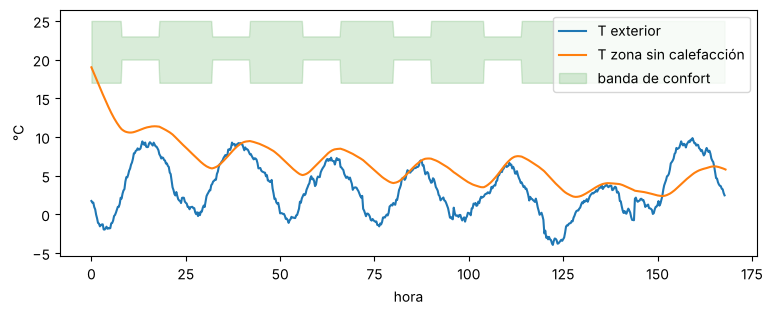

T exterior media de la semana de prueba: 3.35 °C


In [4]:
STEPS_DIA = int(24 / DT)
RHO = 2.0     # €/(K·h): precio que se asigna a cada grado-hora fuera de la banda de confort

def tarifa(horas, finde):
    h = horas % 24
    p = np.where(h < 8, 0.10, 0.15)
    p = np.where(((h >= 10) & (h < 14)) | ((h >= 18) & (h < 22)), 0.22, p)
    return np.where(finde, 0.10, p)

def escenario(n_dias, semilla, dia_semana=0):
    rng = np.random.default_rng(semilla)
    n = n_dias * STEPS_DIA
    horas = np.arange(n) * DT
    dia = (horas // 24).astype(int)
    finde = (dia_semana + dia) % 7 >= 5
    h = horas % 24
    media = 5 + 3 * rng.standard_normal(n_dias)
    amp = 4 + rng.uniform(-1, 1, n_dias)
    ruido = np.zeros(n)
    for k in range(1, n):
        ruido[k] = 0.95 * ruido[k - 1] + 0.3 * rng.standard_normal()
    tout = media[dia] + amp[dia] * np.sin(2 * np.pi * (h - 9) / 24) + ruido
    sol = rng.uniform(0, 2, n_dias)[dia] * np.clip(np.sin(np.pi * (h - 7) / 10), 0, None)
    occ = (~finde) & (h >= 8) & (h < 18)
    return dict(n=n, horas=horas, tout=tout, gan=sol + 0.4 * occ, occ=occ, finde=finde,
                lo=np.where(occ, 20.0, 17.0), hi=np.where(occ, 23.0, 25.0), precio=tarifa(horas, finde))

def paso_planta(T, P, tout, g, R=R_ZONA, C=C_ZONA, f_cop=1.0):
    aa = np.exp(-DT / (R * C))
    return aa * T + (1 - aa) * (tout + R * (f_cop * cop(tout) * P + g))

def indicadores(esc, T, P):
    viol = np.maximum(esc["lo"] - T[1:], 0) + np.maximum(T[1:] - esc["hi"], 0)
    kh = viol.sum() * DT
    coste = (esc["precio"] * P).sum() * DT
    return dict(energia_kWh=P.sum() * DT, coste_eur=coste, confort_Kh=kh, total_eur=coste + RHO * kh)

def simular(esc, politica, T0=19.0, ruido=0.1, semilla=1, R=R_ZONA, C=C_ZONA, f_cop=1.0):
    # politica(k, y) -> P. Devuelve las trayectorias de T (n+1) y P (n).
    rng = np.random.default_rng(semilla)
    T = np.zeros(esc["n"] + 1); P = np.zeros(esc["n"]); T[0] = T0
    for k in range(esc["n"]):
        y = T[k] + ruido * rng.standard_normal()
        P[k] = np.clip(politica(k, y), 0, PMAX)
        T[k + 1] = paso_planta(T[k], P[k], esc["tout"][k], esc["gan"][k], R, C, f_cop)
    return T, P

prueba = escenario(7, semilla=7)          # semana de PRUEBA: no se usa para ajustar nada
T_libre, _ = simular(prueba, lambda k, y: 0.0)
fig, ax = plt.subplots()
ax.plot(prueba["horas"], prueba["tout"], label="T exterior")
ax.plot(np.r_[prueba["horas"], prueba["horas"][-1] + DT], T_libre, label="T zona sin calefacción")
ax.fill_between(prueba["horas"], prueba["lo"], prueba["hi"], color="g", alpha=0.15, label="banda de confort")
ax.set_xlabel("hora"); ax.set_ylabel("°C"); ax.legend(loc="upper right"); plt.show()
print(f"T exterior media de la semana de prueba: {prueba['tout'].mean():.2f} °C")

## Parte 2 · Control PI con ajuste SIMC

Se aproxima la planta por un modelo de primer orden con retardo (FOPDT) $k\,e^{-\theta s}/(\tau s+1)$ con $k=R\cdot\mathrm{COP}(5\,^\circ\mathrm C)=14$ K/kW, $\tau=15$ h y $\theta=\Delta t=0{,}25$ h (el muestreo actúa como un retardo). Las reglas **SIMC** de Skogestad (apuntes, tema 1) dan

$$K_c=\frac{\tau}{k(\tau_c+\theta)},\qquad \tau_I=\min\{\tau,\ 4(\tau_c+\theta)\}.$$

**Ejercicio 2.** Calcula `Kc` y `Ti` con $\tau_c=0{,}5$ h.

**Ejercicio 3.** Completa la clase `PI`: ley posicional $u=K_c e+I$, saturación en $[0,P_{\max}]$ y **anti-windup por integración condicional** (solo se integra si la salida no está saturada o si el error ayuda a desaturar).

In [5]:
k_planta, theta, tau_c = R_ZONA * cop(5.0), DT, 0.5
# TU CÓDIGO
Kc = TAU / (k_planta * (tau_c + theta))
Ti = min(TAU, 4 * (tau_c + theta))
# FIN

In [6]:
# Comprobación
assert abs(Kc - 15 / (14 * 0.75)) < 1e-12 and abs(Ti - 3.0) < 1e-12
print(f"Correcto: Kc = {Kc:.4f} kW/K, τI = {Ti} h")

Correcto: Kc = 1.4286 kW/K, τI = 3.0 h


In [7]:
class PI:
    def __init__(self, Kc, Ti, umin=0.0, umax=PMAX):
        self.Kc, self.Ti, self.umin, self.umax, self.I = Kc, Ti, umin, umax, 0.0
    def __call__(self, consigna, y):
        e = consigna - y
        # TU CÓDIGO
        u = self.Kc * e + self.I
        us = min(max(u, self.umin), self.umax)
        if u == us or np.sign(e) != np.sign(u - us):
            self.I += self.Kc * DT / self.Ti * e
        return us
        # FIN

def consigna_pi(esc, alta=21.0, baja=18.0, inicio=6):
    h = esc["horas"] % 24
    return np.where((~esc["finde"]) & (h >= inicio) & (h < 18), alta, baja)

In [8]:
# Comprobación
c = PI(1.0, 1.0)
assert c(1.0, 0.0) == 1.0 and abs(c.I - 0.25) < 1e-12, "primer paso: u = Kc·e, I = Kc·Δt/Ti·e"
c = PI(1.0, 1.0); [c(10.0, 0.0) for _ in range(50)]
assert c.I < 3.0, "anti-windup: con la salida saturada el integrador no debe crecer sin límite"
sp = consigna_pi(prueba); pi = PI(Kc, Ti)
T_pi, P_pi = simular(prueba, lambda k, y: pi(sp[k], y))
ind_pi = indicadores(prueba, T_pi, P_pi)
assert ind_pi["confort_Kh"] < 0.5
print("Correcto. PI:", {k: round(float(v), 2) for k, v in ind_pi.items()})

Correcto. PI: {'energia_kWh': 175.36, 'coste_eur': 21.06, 'confort_Kh': 0.0, 'total_eur': 21.06}


## Parte 3 · Identificación del gemelo digital

En una planta real no se conocen $R$, $C$ ni la curva del COP: hay que **identificarlos con datos**. Se registran 14 días en **lazo abierto** con una excitación aleatoria por tramos (potencia constante durante 1–4 h, valores entre 0 y 3 kW), que es **persistentemente excitante**. Se separan por **bloques temporales**: días 1–10 para estimar y 11–14 para validar (nunca se barajan las muestras: habría fuga de información entre instantes contiguos).

Se comparan tres modelos de un paso, $\hat T_{k+1}=f(T_k,P_k,T_{{\rm ext},k},G_k)$:

* **ARX** lineal: $\hat T_{k+1}=\theta_1T_k+\theta_2P_k+\theta_3T_{{\rm ext},k}+\theta_4G_k+\theta_5$;
* **NARX con física**: añade el regresor $P_kT_{{\rm ext},k}$, que captura el COP variable (sigue siendo lineal en los parámetros);
* **NARX neuronal**: un perceptrón multicapa (scikit-learn) con las mismas entradas.

Cada uno se valida de dos formas: **predicción a un paso** (se usa la medida real $T_k$) y **simulación libre** (el modelo se realimenta con su propia predicción durante los 4 días de validación), que es lo que necesitan el MPC y el entrenamiento del agente.

In [9]:
def datos_identificacion(n_dias=14, semilla=3):
    esc = escenario(n_dias, semilla)
    rng = np.random.default_rng(semilla + 100)
    P = np.zeros(esc["n"]); k = 0
    while k < esc["n"]:
        dur = rng.integers(4, 17); P[k:k + dur] = rng.uniform(0, PMAX); k += dur
    T = np.zeros(esc["n"] + 1); T[0] = 18.0
    for k in range(esc["n"]):
        T[k + 1] = paso_planta(T[k], P[k], esc["tout"][k], esc["gan"][k])
    y = T + 0.1 * rng.standard_normal(T.shape)          # medidas con ruido
    return esc, P, y

esc_id, P_id, y_id = datos_identificacion()
corte = 10 * STEPS_DIA                                    # días 1-10 estimación, 11-14 validación
def regresores(y, P, esc, fisica=False):
    cols = [y[:-1], P, esc["tout"], esc["gan"], np.ones_like(P)]
    if fisica:
        cols.insert(2, P * esc["tout"])
    return np.column_stack(cols), y[1:]
print("muestras:", len(P_id), "· estimación:", corte, "· validación:", len(P_id) - corte)

muestras: 1344 · estimación: 960 · validación: 384


**Ejercicio 4.** Estima los parámetros por mínimos cuadrados (ecuaciones normales, módulo 8) con `np.linalg.lstsq` sobre los datos de estimación, para el ARX (`th_arx`) y para el NARX con física (`th_fis`).

In [10]:
X, Y = regresores(y_id, P_id, esc_id)
Xf, _ = regresores(y_id, P_id, esc_id, fisica=True)
# TU CÓDIGO
th_arx = np.linalg.lstsq(X[:corte], Y[:corte], rcond=None)[0]
th_fis = np.linalg.lstsq(Xf[:corte], Y[:corte], rcond=None)[0]
# FIN

In [11]:
# Comprobación: los parámetros físicos verdaderos del NARX con física
a_v = np.exp(-DT / TAU)
verdad = np.array([a_v, (1 - a_v) * R_ZONA * 2.5, (1 - a_v) * R_ZONA * 0.06, 1 - a_v, (1 - a_v) * R_ZONA, 0.0])
assert th_arx.shape == (5,) and th_fis.shape == (6,)
assert np.max(np.abs(th_fis - verdad)) < 0.02, "el NARX con física debe recuperar los parámetros verdaderos"
print("NARX con física:", th_fis.round(4)); print("verdaderos:      ", verdad.round(4))
print(f"Constante de tiempo identificada: τ = {-DT / np.log(th_fis[0]):.2f} h (verdadera 15 h)")

NARX con física: [0.9827 0.2094 0.005  0.0169 0.0797 0.0156]
verdaderos:       [0.9835 0.2066 0.005  0.0165 0.0826 0.    ]
Constante de tiempo identificada: τ = 14.33 h (verdadera 15 h)


**Ejercicio 5.** Escribe `simular_libre(f, y0, P, esc)`, que realimenta el modelo de un paso `f(T, P, tout, g)` con su propia salida, y calcula la raíz del error cuadrático medio (RMSE) a un paso y en simulación libre sobre los días de validación.

In [12]:
def simular_libre(f, y0, P, esc):
    # TU CÓDIGO
    T = np.zeros(len(P) + 1); T[0] = y0
    for k in range(len(P)):
        T[k + 1] = f(T[k], P[k], esc["tout"][k], esc["gan"][k])
    return T
    # FIN

f_arx = lambda T, P, to, g: th_arx @ np.array([T, P, to, g, 1.0])
f_fis = lambda T, P, to, g: th_fis @ np.array([T, P, P * to, to, g, 1.0])

esc_val = {k: (v[corte:] if isinstance(v, np.ndarray) else v) for k, v in esc_id.items()}
P_val, y_val = P_id[corte:], y_id[corte:]
def rmse(a, b): return float(np.sqrt(np.mean((a - b) ** 2)))

In [13]:
# Red neuronal NARX (mismas entradas que el ARX; se estandarizan entradas y salida = incremento de T)
Xn = np.column_stack([y_id[:-1], P_id, esc_id["tout"], esc_id["gan"]])
sx = StandardScaler().fit(Xn[:corte])
dY = (y_id[1:] - y_id[:-1])
red = MLPRegressor(hidden_layer_sizes=(32, 32), alpha=1e-4, max_iter=3000, random_state=0,
                   early_stopping=True, validation_fraction=0.15).fit(sx.transform(Xn[:corte]), dY[:corte] * 10)
f_red = lambda T, P, to, g: T + red.predict(sx.transform([[T, P, to, g]]))[0] / 10

tabla = {}
for nombre, f in [("ARX", f_arx), ("NARX con física", f_fis), ("NARX neuronal", f_red)]:
    un_paso = np.array([f(y_val[k], P_val[k], esc_val["tout"][k], esc_val["gan"][k]) for k in range(len(P_val))])
    libre = simular_libre(f, y_val[0], P_val, esc_val)
    tabla[nombre] = (rmse(un_paso, y_val[1:]), rmse(libre[1:], y_val[1:]))
print(f"{'modelo':18s} {'RMSE 1 paso (K)':>16s} {'RMSE simulación (K)':>20s}")
for n_, (r1, rs) in tabla.items():
    print(f"{n_:18s} {r1:16.3f} {rs:20.3f}")

modelo              RMSE 1 paso (K)  RMSE simulación (K)
ARX                           0.137                0.287
NARX con física               0.136                0.180
NARX neuronal                 0.137                0.340


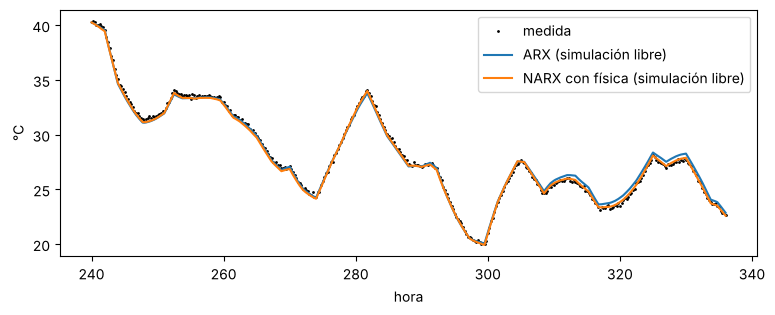

Correcto: la validación en simulación libre discrimina los modelos; la de un paso, no.


In [14]:
# Comprobación
assert tabla["NARX con física"][1] < 0.3, "con la estructura correcta la simulación libre debe ser precisa"
assert tabla["ARX"][1] > tabla["NARX con física"][1], "el ARX lineal no captura el COP variable"
assert all(r1 < 0.2 for r1, _ in tabla.values()), "a un paso todos parecen buenos: por eso no basta con esa métrica"
libre_arx = simular_libre(f_arx, y_val[0], P_val, esc_val); libre_fis = simular_libre(f_fis, y_val[0], P_val, esc_val)
hv = esc_val["horas"]; hv = np.r_[hv, hv[-1] + DT]
plt.plot(hv, y_val, "k.", ms=2, label="medida"); plt.plot(hv, libre_arx, label="ARX (simulación libre)")
plt.plot(hv, libre_fis, label="NARX con física (simulación libre)"); plt.xlabel("hora"); plt.ylabel("°C"); plt.legend(); plt.show()
print("Correcto: la validación en simulación libre discrimina los modelos; la de un paso, no.")

## Parte 4 · MPC económico con el modelo identificado

En cada paso el MPC resuelve, con horizonte $N=96$ (24 h) y previsiones de $T_{\rm ext}$, $G$ y precio,

$$\min_{P,s}\ \Delta t\sum_{j=0}^{N-1}\bigl(c_{k+j}P_j+\rho\,s_j\bigr)\quad\text{s.a.}\quad \hat T_{j+1}=\theta_1\hat T_j+b_jP_j+d_j,\ \ 0\le P_j\le P_{\max},\ \ \underline T_{j+1}+m-s_j\le\hat T_{j+1}\le\overline T_{j+1}-m+s_j,\ \ s_j\ge0,$$

aplica solo $P_0$ y repite (horizonte deslizante). Con el NARX con física, $b_j=\theta_2+\theta_3T_{{\rm ext},j}$ y $d_j=\theta_4T_{{\rm ext},j}+\theta_5G_j+\theta_6$ son conocidos: el problema es un **programa lineal**. Las variables de holgura $s_j$ hacen las restricciones de confort **blandas** (el problema siempre es factible) y $m$ es un **margen** que absorbe el error de modelo y el ruido de medida.

**Ejercicio 6.** Completa la lista de restricciones `restr` del problema en CVXPY.

In [15]:
def crear_mpc(esc, th, N=96, margen=0.3):
    Pv, Tv, s = cp.Variable(N), cp.Variable(N + 1), cp.Variable(N, nonneg=True)
    T0, b, d = cp.Parameter(), cp.Parameter(N), cp.Parameter(N)
    lo, hi, pr = cp.Parameter(N), cp.Parameter(N), cp.Parameter(N, nonneg=True)
    # TU CÓDIGO
    restr = [Tv[0] == T0,
             Tv[1:] == th[0] * Tv[:-1] + cp.multiply(b, Pv) + d,
             Pv >= 0, Pv <= PMAX,
             Tv[1:] >= lo - s, Tv[1:] <= hi + s]
    # FIN
    prob = cp.Problem(cp.Minimize(DT * (pr @ Pv) + RHO * DT * cp.sum(s)), restr)
    ext = lambda x: np.concatenate([x, np.repeat(x[-1:], N)])
    TO, G, LO, HI, PR = (ext(esc[c]) for c in ("tout", "gan", "lo", "hi", "precio"))
    reg = {"t": 0.0, "n": 0}
    def politica(k, y):
        t0 = time.time(); sl = slice(k, k + N)
        T0.value = y
        b.value = th[1] + th[2] * TO[sl]
        d.value = th[3] * TO[sl] + th[4] * G[sl] + th[5]
        lo.value, hi.value, pr.value = LO[sl] + margen, HI[sl] - margen, PR[sl]
        prob.solve(solver=cp.CLARABEL)
        reg["t"] += time.time() - t0; reg["n"] += 1
        return float(Pv.value[0])
    return politica, reg

In [16]:
# Comprobación y simulación de la semana de prueba
mpc, reg = crear_mpc(prueba, th_fis)
T_mpc, P_mpc = simular(prueba, mpc)
ind_mpc = indicadores(prueba, T_mpc, P_mpc)
assert ind_mpc["confort_Kh"] < 0.5 and ind_mpc["coste_eur"] < ind_pi["coste_eur"]
print(f"Correcto. MPC: {({k: round(float(v), 2) for k, v in ind_mpc.items()})}")
print(f"{reg['n']} problemas resueltos, {1000 * reg['t'] / reg['n']:.1f} ms de media cada uno")

Correcto. MPC: {'energia_kWh': 171.12, 'coste_eur': 19.28, 'confort_Kh': 0.0, 'total_eur': 19.28}
672 problemas resueltos, 4.4 ms de media cada uno


MPC sin margen: {'energia_kWh': 166.89, 'coste_eur': 18.76, 'confort_Kh': 3.54, 'total_eur': 25.84}


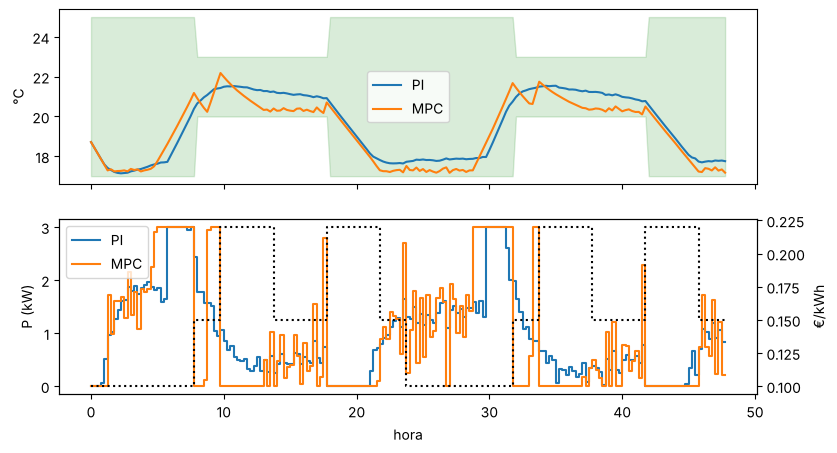

In [17]:
# Sin margen, el error de modelo y el ruido producen pequeñas violaciones
mpc0, _ = crear_mpc(prueba, th_fis, margen=0.0)
T0_, P0_ = simular(prueba, mpc0); ind_mpc0 = indicadores(prueba, T0_, P0_)
print("MPC sin margen:", {k: round(float(v), 2) for k, v in ind_mpc0.items()})
dia = slice(0, 2 * STEPS_DIA); hh = prueba["horas"][dia]
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(9, 5))
ax[0].plot(hh, T_pi[1:][dia], label="PI"); ax[0].plot(hh, T_mpc[1:][dia], label="MPC")
ax[0].fill_between(hh, prueba["lo"][dia], prueba["hi"][dia], color="g", alpha=0.15); ax[0].set_ylabel("°C"); ax[0].legend()
ax[1].step(hh, P_pi[dia], label="PI"); ax[1].step(hh, P_mpc[dia], label="MPC")
ax2 = ax[1].twinx(); ax2.step(hh, prueba["precio"][dia], "k:", label="precio"); ax2.set_ylabel("€/kWh")
ax[1].set_ylabel("P (kW)"); ax[1].set_xlabel("hora"); ax[1].legend(loc="upper left"); plt.show()

## Parte 5 · La planta como entorno Gymnasium

Para entrenar un agente se empaqueta el **gemelo digital** con la interfaz estándar de Gymnasium: `reset(seed)` devuelve `(obs, info)` y `step(accion)` devuelve `(obs, recompensa, terminated, truncated, info)`. Aquí el episodio solo acaba por límite de tiempo: `terminated=False` y `truncated=True` en el último paso (la diferencia importa al calcular objetivos con *bootstrapping*; apuntes, tema 4).

El entorno aplica **aleatorización del dominio**: en cada `reset` muestrea $R$ y $C$ con un ±20 % y el COP con un ±10 %, además de un clima nuevo.

**Ejercicio 7.** Completa la recompensa: $r_k=-\Delta t\,\bigl(c_kP_k+\rho\,v_{k+1}\bigr)$, con $v_{k+1}$ la violación de la banda en $T_{k+1}$ (K).

In [18]:
Base = gym.Env if HAY_GYM else object

class EntornoHVAC(Base):
    # Zona con bomba de calor. Observación: [T medida, T_ext, precio, sen h, cos h, lo actual, lo dentro de 2 h, ocupación en 3 h]
    def __init__(self, n_dias=3, aleatorizar=True, esc=None):
        self.n_dias, self.aleatorizar, self.esc_fijo = n_dias, aleatorizar, esc
        if HAY_GYM:
            self.observation_space = spaces.Box(-50, 50, shape=(8,), dtype=np.float64)
            self.action_space = spaces.Box(0.0, PMAX, shape=(1,), dtype=np.float64)

    def _obs(self):
        e, k = self.esc, self.k; n = e["n"]; h = e["horas"][min(k, n - 1)] % 24
        kk = min(k, n - 1)
        return np.array([self.T + 0.1 * self.rng.standard_normal(), e["tout"][kk], e["precio"][kk],
                         np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24), e["lo"][kk],
                         e["lo"][min(kk + 8, n - 1)], float(e["occ"][kk:kk + 12].any())])

    def reset(self, seed=None, options=None):
        if HAY_GYM:
            super().reset(seed=seed)
            self.rng = self.np_random
        else:
            self.rng = np.random.default_rng(seed)
        self.esc = self.esc_fijo or escenario(self.n_dias, int(self.rng.integers(1e9)), int(self.rng.integers(7)))
        u = self.rng.uniform
        self.R, self.C, self.fc = (R_ZONA * u(0.8, 1.2), C_ZONA * u(0.8, 1.2), u(0.9, 1.1)) if self.aleatorizar else (R_ZONA, C_ZONA, 1.0)
        self.k, self.T = 0, (u(16, 21) if self.esc_fijo is None else 19.0)
        return self._obs(), {}

    def step(self, accion):
        e, k = self.esc, self.k
        P = float(np.clip(np.asarray(accion).ravel()[0], 0, PMAX))
        self.T = paso_planta(self.T, P, e["tout"][k], e["gan"][k], self.R, self.C, self.fc)
        v = max(e["lo"][k] - self.T, 0) + max(self.T - e["hi"][k], 0)
        # TU CÓDIGO
        r = -DT * (e["precio"][k] * P + RHO * v)
        # FIN
        self.k += 1
        truncated = self.k >= e["n"]
        return self._obs(), r, False, truncated, {"P": P, "T": self.T, "violacion": v}

In [19]:
# Comprobación: un episodio con una política aleatoria
env = EntornoHVAC()
obs, _ = env.reset(seed=0); ret, pasos = 0.0, 0
while True:
    obs, r, term, trunc, info = env.step(np.random.default_rng(pasos).uniform(0, PMAX, 1))
    ret += r; pasos += 1
    assert r <= 0
    if term or trunc: break
assert pasos == 3 * STEPS_DIA and obs.shape == (8,)
if HAY_GYM:
    import warnings
    from gymnasium.utils.env_checker import check_env
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always")
        check_env(EntornoHVAC(), skip_render_check=True)
    for w in avisos:   # el comprobador recomienda acciones normalizadas en [-1, 1] o [0, 1]
        print("Aviso de check_env:", str(w.message).split(". See")[0])
print(f"Correcto: {pasos} pasos, retorno de la política aleatoria = {ret:.2f} €")

Aviso de check_env: WARN: For Box action spaces, we recommend using a symmetric and normalized space (range=[-1, 1] or [0, 1])
Correcto: 288 pasos, retorno de la política aleatoria = -921.57 €


## Parte 6 · Agente: búsqueda de política con aleatorización del dominio

Un agente pequeño y rápido: política **paramétrica** $P=P_{\max}\,\sigma(w^\top\phi(o))$, donde $\phi$ son las 8 observaciones escaladas, y optimización de $w$ por el **método de entropía cruzada** (CEM), una búsqueda de política sin gradiente (apuntes, tema 4): se muestrean $w\sim\mathcal N(\mu,\operatorname{diag}\sigma^2)$, se evalúa el retorno medio de cada candidato en varios episodios aleatorizados (con los **mismos** escenarios para todos los candidatos de una iteración) y se reajustan $\mu,\sigma$ con la élite. El simulador se vectoriza sobre la población para que el entrenamiento tarde segundos.

**Ejercicio 8.** Completa la actualización de CEM: selecciona los `elite` mejores y recalcula `mu` y `sd` (añade 0,02 a la desviación para no colapsar la búsqueda).

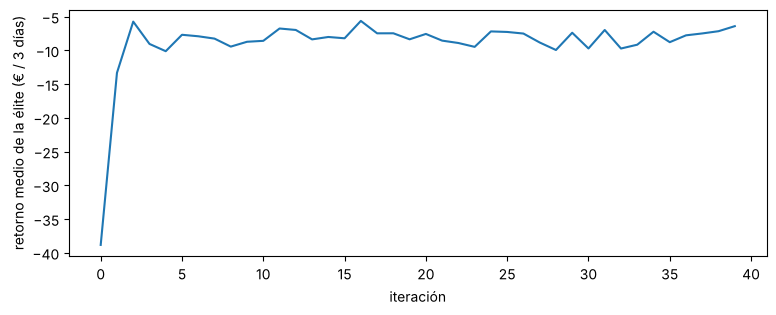

Entrenamiento: 3.2 s · w = [ 1.49 -1.85  1.52 -0.34 -2.18 -0.06 -0.68  3.13]


In [20]:
def rasgos(obs):                                         # obs: (pop, 8) -> (pop, 8)
    T, to, pr, s, c, lo, lo2, occ = obs.T
    return np.column_stack([np.ones_like(T), T - lo, lo2 - T, 10 * pr, to / 10, s, c, occ])

def accion(W, obs):
    z = np.einsum("pf,pf->p", W, rasgos(obs))
    return PMAX / (1 + np.exp(-np.clip(z, -30, 30)))

def retorno_poblacion(W, esc, R, C, fc, T0):
    # Simula a la vez los len(W) candidatos en el mismo escenario y la misma planta.
    T = np.full(len(W), T0); J = np.zeros(len(W)); n = esc["n"]
    for k in range(n):
        h = esc["horas"][k] % 24
        o = np.column_stack([T, np.full_like(T, esc["tout"][k]), np.full_like(T, esc["precio"][k]),
                             np.full_like(T, np.sin(2*np.pi*h/24)), np.full_like(T, np.cos(2*np.pi*h/24)),
                             np.full_like(T, esc["lo"][k]), np.full_like(T, esc["lo"][min(k + 8, n - 1)]),
                             np.full_like(T, float(esc["occ"][k:k + 12].any()))])
        P = accion(W, o)
        T = paso_planta(T, P, esc["tout"][k], esc["gan"][k], R, C, fc)
        v = np.maximum(esc["lo"][k] - T, 0) + np.maximum(T - esc["hi"][k], 0)
        J -= DT * (esc["precio"][k] * P + RHO * v)
    return J

def cem(iters=40, pop=60, elite=12, n_ep=4, semilla=0):
    rng = np.random.default_rng(semilla)
    mu, sd, hist = np.zeros(8), np.ones(8), []
    for it in range(iters):
        W = mu + sd * rng.standard_normal((pop, 8))
        J = np.zeros(pop)
        for e in range(n_ep):                            # escenarios de ENTRENAMIENTO (semillas >= 1000)
            esc = escenario(3, 1000 + 10 * it + e, int(rng.integers(7)))
            J += retorno_poblacion(W, esc, R_ZONA * rng.uniform(0.8, 1.2), C_ZONA * rng.uniform(0.8, 1.2),
                                   rng.uniform(0.9, 1.1), rng.uniform(16, 21)) / n_ep
        # TU CÓDIGO
        idx = np.argsort(J)[-elite:]
        mu, sd = W[idx].mean(0), W[idx].std(0) + 0.02
        # FIN
        hist.append(float(J[idx].mean()))
    return mu, hist

t0 = time.time(); w_rl, hist = cem(); t_rl = time.time() - t0
plt.plot(hist); plt.xlabel("iteración"); plt.ylabel("retorno medio de la élite (€ / 3 días)"); plt.show()
print(f"Entrenamiento: {t_rl:.1f} s · w = {w_rl.round(2)}")

In [21]:
# Comprobación: evaluación en la semana de PRUEBA a través del entorno
def evaluar_en_entorno(politica_obs, esc, semilla=1):
    env = EntornoHVAC(aleatorizar=False, esc=esc); obs, _ = env.reset(seed=semilla)
    T, P = [env.T], []
    while True:
        obs, r, term, trunc, info = env.step([politica_obs(obs)])
        T.append(info["T"]); P.append(info["P"])
        if term or trunc: break
    return np.array(T), np.array(P)

pol_rl = lambda o: accion(w_rl[None], o[None])[0]
T_rl, P_rl = evaluar_en_entorno(pol_rl, prueba)
ind_rl = indicadores(prueba, T_rl, P_rl)
assert ind_rl["total_eur"] < ind_pi["total_eur"] * 1.15, "el agente debe acercarse al PI o mejorarlo"
print("Correcto. RL (CEM):", {k: round(float(v), 2) for k, v in ind_rl.items()})

Correcto. RL (CEM): {'energia_kWh': 169.91, 'coste_eur': 20.63, 'confort_Kh': 0.01, 'total_eur': 20.65}


**Opcional: SAC con Stable-Baselines3.** Si tienes `stable-baselines3` instalado, la celda siguiente entrena un agente SAC sobre el mismo entorno (tarda varios minutos; por eso está desactivada). Compara su resultado con el de CEM.

In [22]:
USAR_SB3 = False
if USAR_SB3:
    from stable_baselines3 import SAC
    modelo = SAC("MlpPolicy", EntornoHVAC(), learning_rate=3e-4, gamma=0.99, verbose=0, seed=0)
    modelo.learn(total_timesteps=50_000)
    T_sac, P_sac = evaluar_en_entorno(lambda o: float(modelo.predict(o, deterministic=True)[0][0]), prueba)
    print("SAC:", indicadores(prueba, T_sac, P_sac))
else:
    print("Celda opcional desactivada (USAR_SB3 = False).")

Celda opcional desactivada (USAR_SB3 = False).


## Parte 7 · Comparación y robustez

Los tres controladores se evalúan en la misma semana de prueba, con el mismo ruido de medida. Después se repite la evaluación con una planta **distinta del modelo** ($R$ un 20 % mayor, $C$ un 20 % menor y un COP un 10 % peor), que imita el salto entre el gemelo digital y la planta real.

**Ejercicio 9.** Calcula el ahorro porcentual en coste de energía del MPC y del agente respecto al PI, `ahorro_mpc` y `ahorro_rl`.

In [23]:
res = {"PI": ind_pi, "MPC": ind_mpc, "RL (CEM)": ind_rl}
# TU CÓDIGO
ahorro_mpc = 100 * (1 - ind_mpc["coste_eur"] / ind_pi["coste_eur"])
ahorro_rl = 100 * (1 - ind_rl["coste_eur"] / ind_pi["coste_eur"])
# FIN
print(f"{'':10s} {'energía kWh':>12s} {'coste €':>9s} {'confort K·h':>12s} {'total €':>9s}")
for n_, d_ in res.items():
    print(f"{n_:10s} {d_['energia_kWh']:12.1f} {d_['coste_eur']:9.2f} {d_['confort_Kh']:12.2f} {d_['total_eur']:9.2f}")
print(f"Ahorro en coste frente al PI: MPC {ahorro_mpc:.1f} %, RL {ahorro_rl:.1f} %")

            energía kWh   coste €  confort K·h   total €
PI                175.4     21.06         0.00     21.06
MPC               171.1     19.28         0.00     19.28
RL (CEM)          169.9     20.63         0.01     20.65
Ahorro en coste frente al PI: MPC 8.4 %, RL 2.1 %


In [24]:
# Comprobación
assert abs(ahorro_mpc - 100 * (ind_pi["coste_eur"] - ind_mpc["coste_eur"]) / ind_pi["coste_eur"]) < 1e-9
assert ahorro_mpc > 0
# Robustez: planta distinta del modelo
kw = dict(R=1.2 * R_ZONA, C=0.8 * C_ZONA, f_cop=0.9)
pi2 = PI(Kc, Ti); T_a, P_a = simular(prueba, lambda k, y: pi2(sp[k], y), **kw)
mpc2, _ = crear_mpc(prueba, th_fis); T_b, P_b = simular(prueba, mpc2, **kw)
def pol_rl_k(k, y):
    e = prueba; n = e["n"]; h = e["horas"][k] % 24
    o = np.array([[y, e["tout"][k], e["precio"][k], np.sin(2*np.pi*h/24), np.cos(2*np.pi*h/24),
                   e["lo"][k], e["lo"][min(k + 8, n - 1)], float(e["occ"][k:k + 12].any())]])
    return accion(w_rl[None], o)[0]
T_c, P_c = simular(prueba, pol_rl_k, **kw)
rob = {"PI": indicadores(prueba, T_a, P_a), "MPC": indicadores(prueba, T_b, P_b), "RL (CEM)": indicadores(prueba, T_c, P_c)}
print("Planta perturbada (R +20 %, C -20 %, COP -10 %):")
for n_, d_ in rob.items():
    print(f"{n_:10s} coste {d_['coste_eur']:6.2f} €   confort {d_['confort_Kh']:5.2f} K·h   total {d_['total_eur']:6.2f} €")
print("Correcto.")

Planta perturbada (R +20 %, C -20 %, COP -10 %):
PI         coste  18.75 €   confort  0.00 K·h   total  18.75 €
MPC        coste  17.28 €   confort  0.00 K·h   total  17.28 €
RL (CEM)   coste  18.50 €   confort  0.00 K·h   total  18.50 €
Correcto.


## Parte 8 · Batería con precios horarios

Una batería de $E_{\max}=10$ kWh y $P_{\max}=5$ kW, con rendimientos de carga y descarga $\eta=0{,}95$, compra y vende energía a precios horarios conocidos durante 24 h, y cada kWh que pasa por ella cuesta $c_{\rm deg}=0{,}01$ € de degradación. Con $c_t\ge0$ y $d_t\ge0$ las potencias de carga y descarga:

$$\max\sum_t\bigl(p_t(d_t-c_t)-c_{\rm deg}(c_t+d_t)\bigr)\quad\text{s.a.}\quad e_{t+1}=e_t+\eta c_t-d_t/\eta,\ \ 0\le e_t\le E_{\max},\ \ e_0=e_{24}=5,\ \ 0\le c_t,d_t\le P_{\max}.$$

Es un **programa lineal**. También es un MDP determinista con estado $(t,e_t)$: se resuelve por **programación dinámica** hacia atrás sobre una rejilla de estados de carga.

**Ejercicio 10.** Completa la recursión de Bellman hacia atrás `V[t, i] = max_j (beneficio(t, i -> j) + V[t+1, j])`.

In [25]:
precios = np.array([0.08, 0.07, 0.06, 0.06, 0.07, 0.09, 0.13, 0.18, 0.20, 0.17, 0.14, 0.12,
                    0.11, 0.10, 0.10, 0.12, 0.15, 0.19, 0.24, 0.26, 0.22, 0.16, 0.12, 0.10])
EMAX, PB, ETA, CDEG, E0 = 10.0, 5.0, 0.95, 0.01, 5.0
c, d, e = cp.Variable(24, nonneg=True), cp.Variable(24, nonneg=True), cp.Variable(25)
lp = cp.Problem(cp.Maximize(precios @ (d - c) - CDEG * cp.sum(c + d)),
                [e[0] == E0, e[24] == E0, e[1:] == e[:-1] + ETA * c - d / ETA, e >= 0, e <= EMAX, c <= PB, d <= PB])
lp.solve(solver=cp.CLARABEL)
print(f"LP: beneficio óptimo = {lp.value:.4f} €")

rejilla = np.linspace(0, EMAX, 81)                     # pasos de 0,125 kWh
def beneficio(t, e1, e2):
    de = e2 - e1                                        # variación de energía almacenada
    if de >= 0:
        cc = de / ETA
        return -np.inf if cc > PB + 1e-9 else -precios[t] * cc - CDEG * cc
    dd = -de * ETA
    return -np.inf if dd > PB + 1e-9 else precios[t] * dd - CDEG * dd
G = np.array([[[beneficio(t, a_, b_) for b_ in rejilla] for a_ in rejilla] for t in range(24)])
V = np.full((25, len(rejilla)), -np.inf); V[24, np.argmin(abs(rejilla - E0))] = 0.0
for t in range(23, -1, -1):
    # TU CÓDIGO
    V[t] = np.max(G[t] + V[t + 1][None, :], axis=1)
    # FIN
i0 = np.argmin(abs(rejilla - E0))
print(f"PD: beneficio óptimo = {V[0, i0]:.4f} €")

LP: beneficio óptimo = 1.8842 €
PD: beneficio óptimo = 1.8837 €


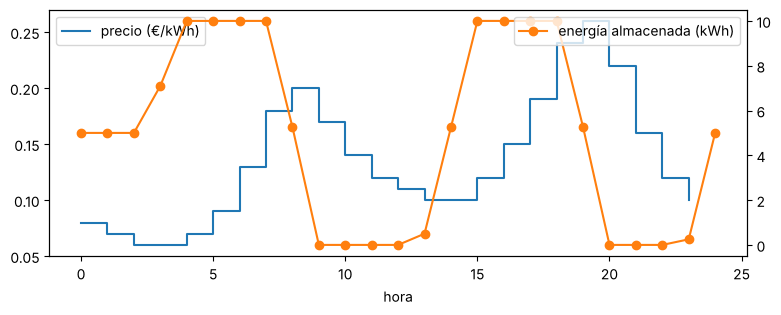

Correcto: LP 1.8842 € · PD 1.8837 € · ciclos equivalentes 1.90


In [26]:
# Comprobación
assert abs(V[0, i0] - lp.value) < 0.02, "la PD sobre la rejilla debe aproximar el óptimo del LP"
assert V[0, i0] <= lp.value + 1e-6, "la rejilla restringe las decisiones: no puede superar al LP"
fig, ax = plt.subplots(); ax.step(range(24), precios, where="post", label="precio (€/kWh)")
ax2 = ax.twinx(); ax2.plot(range(25), e.value, "o-", c="C1", label="energía almacenada (kWh)")
ax.set_xlabel("hora"); ax.legend(loc="upper left"); ax2.legend(loc="upper right"); plt.show()
print(f"Correcto: LP {lp.value:.4f} € · PD {V[0, i0]:.4f} € · ciclos equivalentes {d.value.sum() / EMAX:.2f}")

## Parte 9 · Reactor por lotes: estabilidad térmica y filtro de seguridad

Reacción exotérmica de primer orden A → B en un reactor por lotes de $V=1$ m³ refrigerado por una camisa a temperatura $T_j$:

$$\dot C_A=-k(T)C_A,\qquad \rho c_pV\,\dot T=(-\Delta H)\,k(T)\,C_AV-UA\,(T-T_j),\qquad k(T)=k_{\rm ref}\,e^{-\frac{E}{R}\left(\frac1T-\frac1{T_{\rm ref}}\right)}.$$

Datos: $\rho c_pV=4000$ kJ/K, $-\Delta H=100$ kJ/mol, $C_{A,0}=2000$ mol/m³, $E/R=10\,000$ K, $k_{\rm ref}=10^{-4}$ s⁻¹ a $T_{\rm ref}=350$ K, $UA=2$ kW/K. El calor generado es $Q_g(T)=(-\Delta H)k(T)C_AV$ y el retirado $Q_r=UA(T-T_j)$. Un punto de equilibrio es **estable** si $Q_g'(T)<UA$ (criterio de Semenov; apuntes, tema 5).

**Ejercicio 11.** Calcula `Qg` y su derivada `dQg` en $T=350$ K con $C_A=C_{A,0}$, y la temperatura de camisa `Tj_eq` que equilibra ese punto. ¿Es estable?

In [27]:
RCPV, DH, CA0, ER, KREF, TREF, UA = 4000.0, 100.0, 2000.0, 1e4, 1e-4, 350.0, 2.0
kT = lambda T: KREF * np.exp(-ER * (1 / T - 1 / TREF))
# TU CÓDIGO
Qg = DH * kT(350.0) * CA0          # kW (kJ/s), con V = 1 m³
dQg = Qg * ER / 350.0 ** 2         # derivada de la exponencial de Arrhenius
Tj_eq = 350.0 - Qg / UA
# FIN

Correcto: Qg = 20.0 kW, Qg' = 1.633 kW/K < UA = 2.0 kW/K -> estable; T_j de equilibrio = 340.0 K
Equilibrio inestable: 355.23 K · tangencia en T = 352.69 K con T_j crítica = 340.26 K


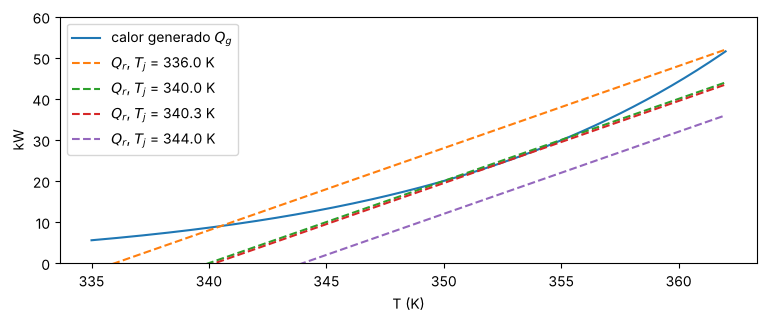

T0 = 354.0 K, T_j = 340.0 K -> T a las 8 h: 350.9 K
T0 = 356.0 K, T_j = 340.0 K -> T a las 8 h: 400.9 K
Filtro: 65 % de las propuestas aleatorias modificadas; máximo aplicado 339.26 K


In [28]:
# Comprobación
assert abs(Qg - 20.0) < 1e-9 and abs(dQg - 20 * 1e4 / 350 ** 2) < 1e-9 and abs(Tj_eq - 340.0) < 1e-9
print(f"Correcto: Qg = {Qg:.1f} kW, Qg' = {dQg:.3f} kW/K {'<' if dQg < UA else '>'} UA = {UA} kW/K -> "
      f"{'estable' if dQg < UA else 'inestable'}; T_j de equilibrio = {Tj_eq:.1f} K")
# Equilibrio inestable superior y temperatura crítica de camisa (tangencia de Semenov), con C_A = C_A0
from scipy.optimize import brentq
Qg_f = lambda T: DH * kT(T) * CA0
T_u = brentq(lambda T: Qg_f(T) - UA * (T - Tj_eq), 352, 380)
T_tan = brentq(lambda T: Qg_f(T) - UA * T ** 2 / ER, 350.5, 370); Tj_crit = T_tan - T_tan ** 2 / ER
print(f"Equilibrio inestable: {T_u:.2f} K · tangencia en T = {T_tan:.2f} K con T_j crítica = {Tj_crit:.2f} K")
TT = np.linspace(335, 362, 200)
plt.plot(TT, Qg_f(TT), label="calor generado $Q_g$")
for tj in (336.0, Tj_eq, Tj_crit, 344.0):
    plt.plot(TT, UA * (TT - tj), "--", label=f"$Q_r$, $T_j$ = {tj:.1f} K")
plt.ylim(0, 60); plt.xlabel("T (K)"); plt.ylabel("kW"); plt.legend(); plt.show()

# Fase inicial del lote (C_A ≈ C_A0): por debajo de T_u la temperatura vuelve; por encima, se dispara
def fase_inicial(T0, Tj, horas=8.0, dt=10.0):
    T = T0
    for _ in range(int(horas * 3600 / dt)):
        T += dt * (Qg_f(T) - UA * (T - Tj)) / RCPV
        if T > 400: break
    return T
for T0 in (354.0, 356.0):
    print(f"T0 = {T0} K, T_j = {Tj_eq} K -> T a las 8 h: {fase_inicial(T0, Tj_eq):.1f} K")

# Filtro de seguridad: cualquier controlador (PI, MPC o agente) propone T_j; el filtro la acota
def filtro_seguridad(Tj_prop, T, margen=1.0):
    if T > T_u - 2.0:                    # cerca de la separatriz: refrigeración máxima
        return 290.0
    return float(np.clip(Tj_prop, 290.0, Tj_crit - margen))
props = np.random.default_rng(0).uniform(280, 370, 1000); temps = np.random.default_rng(1).uniform(340, 360, 1000)
seg = np.array([filtro_seguridad(p, t) for p, t in zip(props, temps)])
assert seg.max() <= Tj_crit - 1.0 and np.all(seg[temps > T_u - 2.0] == 290.0)
print(f"Filtro: {np.mean(seg != props) * 100:.0f} % de las propuestas aleatorias modificadas; máximo aplicado {seg.max():.2f} K")

## Parte 10 · Retos

1. **Previsiones con error.** Pasa al MPC previsiones de $T_{\rm ext}$ con un error AR(1) de 1 K. ¿Cuánto empeora? ¿Qué margen $m$ lo compensa?
2. **Horizonte.** Repite la Parte 4 con $N=16,\,32,\,64$. ¿A partir de qué horizonte deja de mejorar el coste? Relaciónalo con la duración de los periodos tarifarios.
3. **Recompensa.** Cambia $\rho$ a 0,5 y a 10 €/(K·h) en el entrenamiento del agente. ¿Cómo cambia el compromiso energía-confort?
4. **Sin aleatorización.** Entrena el agente con `R`, `C` y COP fijos y evalúalo en la planta perturbada de la Parte 7. ¿Pierde robustez?
5. **SAC.** Activa `USAR_SB3` y compara SAC con CEM en coste, confort y tiempo de cómputo.
6. **Identificación en lazo cerrado.** Identifica el ARX con los datos generados por el PI de la Parte 2. ¿Recuperas los parámetros? (apuntes, tema 2, proposición sobre la identificabilidad en lazo cerrado).

---
### Soluciones de referencia
Inténtalo antes de mirar. (En esta versión guardada las soluciones ya están en las celdas `# TU CÓDIGO`.)

In [29]:
# --- Ejercicio 1 ---
# a = np.exp(-DT / TAU); a_euler = 1 - DT / TAU; dt_max = 2 * TAU      # |1 - Δt/τ| < 1  <=>  Δt < 2τ
# --- Ejercicio 2 ---
# Kc = TAU / (k_planta * (tau_c + theta)); Ti = min(TAU, 4 * (tau_c + theta))
# --- Ejercicio 3 ---
# u = self.Kc * e + self.I; us = min(max(u, self.umin), self.umax)
# if u == us or np.sign(e) != np.sign(u - us): self.I += self.Kc * DT / self.Ti * e
# return us
# --- Ejercicio 4 ---
# th_arx = np.linalg.lstsq(X[:corte], Y[:corte], rcond=None)[0]
# th_fis = np.linalg.lstsq(Xf[:corte], Y[:corte], rcond=None)[0]
# --- Ejercicio 5 ---
# T = np.zeros(len(P) + 1); T[0] = y0
# for k in range(len(P)): T[k + 1] = f(T[k], P[k], esc["tout"][k], esc["gan"][k])
# return T
# --- Ejercicio 6 ---
# restr = [Tv[0] == T0, Tv[1:] == th[0] * Tv[:-1] + cp.multiply(b, Pv) + d,
#          Pv >= 0, Pv <= PMAX, Tv[1:] >= lo - s, Tv[1:] <= hi + s]
# --- Ejercicio 7 ---
# r = -DT * (e["precio"][k] * P + RHO * v)
# --- Ejercicio 8 ---
# idx = np.argsort(J)[-elite:]; mu, sd = W[idx].mean(0), W[idx].std(0) + 0.02
# --- Ejercicio 9 ---
# ahorro_mpc = 100 * (1 - ind_mpc["coste_eur"] / ind_pi["coste_eur"])
# --- Ejercicio 10 ---
# V[t] = np.max(G[t] + V[t + 1][None, :], axis=1)
# --- Ejercicio 11 ---
# Qg = DH * kT(350.0) * CA0; dQg = Qg * ER / 350.0**2; Tj_eq = 350.0 - Qg / UA

In [30]:
print(f"Tiempo total de ejecución del cuaderno: {time.time() - T_INICIO:.1f} s")

Tiempo total de ejecución del cuaderno: 13.6 s
